# Lesson 6 Exercise: Visualize Attention Patterns in Pretrained Models

**Estimated Time:** 18 minutes

## Overview

Dive deep into what pretrained Transformers have learned! You'll extract attention weights from multiple layers and heads, create visualization tools to interpret them, and discover that **different attention heads specialize in different linguistic phenomena** (syntax, coreference, semantic similarity).

## Scenario

Before deploying BERT for content moderation, your ML team wants to understand what it's actually learning. Visualize attention patterns to verify the model is focusing on contextually relevant words when detecting toxic language. This **interpretability analysis builds trust** in the model's decision-making.

---

## What You'll Do

**Part A:** Extract and Visualize Basic Attention (6 min)
- Load BERT and tokenizer
- Process example text with ambiguous "bank"
- Examine positional encoding
- Extract attention weights from all layers
- Plot attention heatmap for Layer 6, Head 0

**Part B:** Compare Multiple Attention Heads (6 min)
- Visualize 4 different attention heads from same layer
- Create 2×2 subplot grid
- Observe: Do different heads show different patterns?
- Hypothesis: Some focus on nearby words, others on syntax

**Part C:** Analyze Layer-by-Layer Attention (6 min)
- Pick one attention head (Head 0)
- Visualize across Layers 1, 4, 8, 12
- Compare: Do early layers differ from late layers?
- Discovery: Early = syntax, late = semantics

---

## Setup

In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from transformers import AutoModel, AutoTokenizer
import warnings
warnings.filterwarnings('ignore')

# Import utilities
from data import load_jigsaw_dataset
from attention_utils import (
    plot_attention_heatmap,
    plot_multihead_attention,
    plot_layer_progression,
    extract_attention_patterns,
    print_attention_patterns
)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
print("\n✓ Setup complete!")

Using device: cpu

✓ Setup complete!


---

# Part A: Extract and Visualize Basic Attention (6 minutes)

## Step 1: Load BERT and Tokenizer

**TODO:** Load the pretrained BERT model and tokenizer.

In [2]:
print("Loading BERT model and tokenizer...\n")

# TODO: Load BERT model and tokenizer
# Hint: Use 'bert-base-uncased'
# Hint: Set output_attentions=True to get attention weights

model_name = 'bert-base-uncased'

# Load tokenizer
tokenizer = AutoTokenizer.from_pretrained(model_name)

# Load model with output_attentions=True
model = AutoModel.from_pretrained(model_name, output_attentions=True)

# Move model to device and set to eval mode
model.to(device)
model.eval()

print("✓ BERT loaded successfully!")

Loading BERT model and tokenizer...



I0000 00:00:1795547534.092902 3437853 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1795547534.132708 3437853 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1795547534.959640 3437853 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
Skipping import of cpp extensions due to incompatible torch version 2.8.0+cu128 for torchao version 0.15.0             Please see http

✓ BERT loaded successfully!


## Step 2: Process Example Text

We'll use the classic example: **"The bank can refuse to lend money to the person by the river bank."**

**TODO:** Tokenize the example and prepare inputs.

In [3]:
print("Loading example text for attention visualization...\n")

# Load Jigsaw dataset (or fallback to synthetic)
comments = load_jigsaw_dataset(n_samples=1000)

# comments with good length for attention visualization (10-30 tokens)
good_examples = [c for c in comments if 10 < c['length'] < 30]

if good_examples:
    example_text = good_examples[0]['text']
else:
    # Fallback to a curated example if none found
    example_text = "The bank can refuse to lend money to the person by the river bank."

print("Example Text:")
print(f"  '{example_text}'\n")

# Tokenize
inputs = tokenizer(example_text, return_tensors='pt', add_special_tokens=True)

# Move to device
inputs = {k: v.to(device) for k, v in inputs.items()}

# Get tokens
tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

print("\nTokenization:")
print(f"  Tokens: {tokens}")
print(f"  Number of tokens: {len(tokens)}")

Loading example text for attention visualization...

Loading Toxic Comment Classification dataset...
Requesting 1000 samples...


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00002.parquet:   0%|          | 0.00/194M [00:00<?, ?B/s]

data/train-00001-of-00002.parquet:   0%|          | 0.00/187M [00:00<?, ?B/s]

data/validation-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/20.8M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/1804874 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/97320 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/97320 [00:00<?, ? examples/s]

✓ Loaded 1000 comments from civil_comments dataset

Example Text:
  'Kay's is one of the best bars in the city, but you don't have a section for the neighborhood.'


Tokenization:
  Tokens: ['[CLS]', 'kay', "'", 's', 'is', 'one', 'of', 'the', 'best', 'bars', 'in', 'the', 'city', ',', 'but', 'you', 'don', "'", 't', 'have', 'a', 'section', 'for', 'the', 'neighborhood', '.', '[SEP]']
  Number of tokens: 27


## Step 3: Examine Position IDs

**TODO:** Display the positional encoding to understand how Transformers know word order.

In [4]:
print("Positional Encoding:")

# Extract or create position_ids
# Hint: If 'position_ids' not in inputs, create with torch.arange()
if 'position_ids' in inputs:
    position_ids = inputs['position_ids'][0].tolist()
else:
    # TODO: Create position_ids
    seq_len = inputs['input_ids'].shape[1]
    position_ids = torch.arange(seq_len, dtype=torch.long, device=device).tolist()

print(f"  Position IDs: {position_ids}")
print("\n💡 Key Insight:")
print("   These position IDs tell BERT the order of tokens.")
print("   Unlike RNNs, Transformers process all tokens in parallel!")

Positional Encoding:
  Position IDs: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]

💡 Key Insight:
   These position IDs tell BERT the order of tokens.
   Unlike RNNs, Transformers process all tokens in parallel!


## Step 4: Extract Attention Weights

**TODO:** Run the model and extract attention weights from all layers.

In [5]:
print("Running model to extract attention weights...\n")

# Run model forward pass
with torch.no_grad():
    outputs = model(**inputs)

# Extract attention weights
# outputs.attentions is a tuple of attention tensors
attention_weights = outputs.attentions

print("Attention Structure:")
print(f"  Number of layers: {len(attention_weights)}")
print(f"  Shape per layer: {attention_weights[0].shape}")
print(f"  Format: (batch_size, n_heads, seq_len, seq_len)")
print("\n✓ Attention weights extracted!")

Running model to extract attention weights...

Attention Structure:
  Number of layers: 12
  Shape per layer: torch.Size([1, 12, 27, 27])
  Format: (batch_size, n_heads, seq_len, seq_len)

✓ Attention weights extracted!


## Step 5: Plot Attention Heatmap for Layer 6, Head 0

**TODO:** Visualize attention weights for a specific layer and head.

Visualizing Layer 6, Head 0...



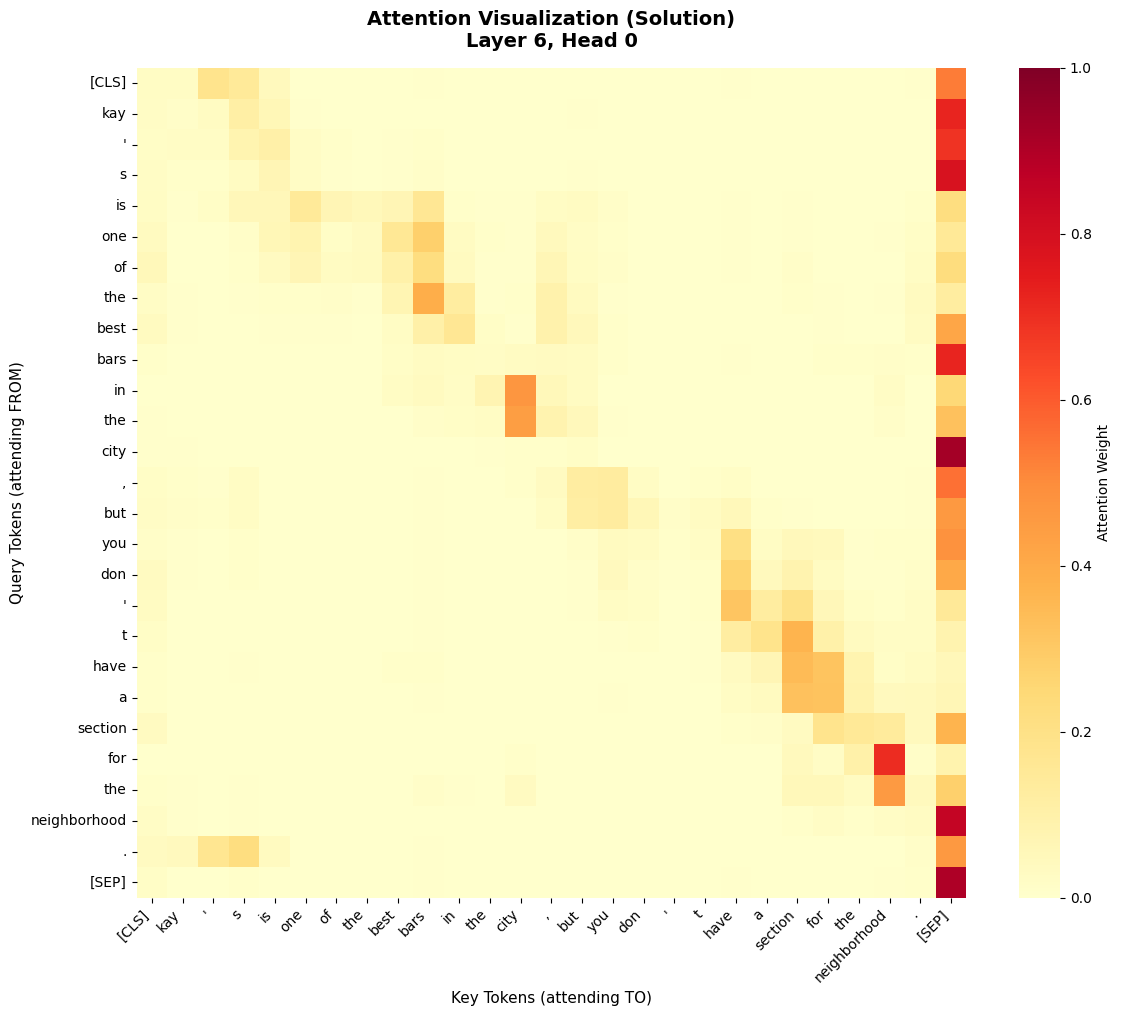

ATTENTION PATTERNS (Top-3 attended tokens per query)

'[CLS]' (pos 0) attends to:
  • '[SEP]' (pos 26): 0.533
  • ''' (pos 2): 0.182
  • 's' (pos 3): 0.148

'kay' (pos 1) attends to:
  • '[SEP]' (pos 26): 0.725
  • 's' (pos 3): 0.112
  • 'is' (pos 4): 0.062

''' (pos 17) attends to:
  • 'have' (pos 19): 0.313
  • 'section' (pos 21): 0.196
  • '[SEP]' (pos 26): 0.152

's' (pos 3) attends to:
  • '[SEP]' (pos 26): 0.789
  • 'is' (pos 4): 0.067
  • 's' (pos 3): 0.028

'is' (pos 4) attends to:
  • '[SEP]' (pos 26): 0.220
  • 'bars' (pos 9): 0.162
  • 'one' (pos 5): 0.148

'one' (pos 5) attends to:
  • 'bars' (pos 9): 0.278
  • 'best' (pos 8): 0.156
  • '[SEP]' (pos 26): 0.153

'of' (pos 6) attends to:
  • '[SEP]' (pos 26): 0.228
  • 'bars' (pos 9): 0.219
  • 'best' (pos 8): 0.100

'the' (pos 23) attends to:
  • 'neighborhood' (pos 24): 0.454
  • '[SEP]' (pos 26): 0.278
  • 'for' (pos 22): 0.054

... (16 more tokens)


In [6]:
# Select Layer 6, Head 0
layer_idx = 5  # 0-indexed, so layer 6 = index 5
head_idx = 0

print(f"Visualizing Layer {layer_idx+1}, Head {head_idx}...\n")

# Extract attention matrix for this layer and head
# Hint: attention_weights[layer_idx][0] gives (n_heads, seq_len, seq_len)
# Hint: Then select head_idx and convert to numpy
attn_layer = attention_weights[layer_idx][0]  # (n_heads, seq_len, seq_len)
attn_head = attn_layer[head_idx].cpu().numpy()  # (seq_len, seq_len)

# Plot attention heatmap
# plot_attention_heatmap() from attention_utils
fig = plot_attention_heatmap(
    attn_head,
    tokens,
    title="Attention Visualization (Solution)",
    layer=layer_idx+1,
    head=head_idx,
    figsize=(12, 10)
)
plt.show()

# Print patterns
patterns = extract_attention_patterns(attn_head, tokens, top_k=3)
print_attention_patterns(patterns, max_tokens=8)

### Analysis Questions (Part A)

Look at your attention heatmap and answer:

1. **What patterns do you see?**
   - Is there a diagonal pattern (self-attention)?
   - Which tokens attend strongly to each other?

2. **"Bank" disambiguation:**
   - Where does the first "bank" (financial) attend?
   - Where does the second "bank" (river) attend?
   - Are they attending to different words?

**TODO:** Write your observations (2-3 sentences):

**YOUR ANALYSIS HERE:**

I observe that...




---

# Part B: Compare Multiple Attention Heads (6 minutes)

Now let's see if different attention heads learn different patterns!

## TODO: Visualize 4 Different Heads

Create a 2×2 grid comparing Heads 0, 3, 7, and 11 from Layer 6.

Comparing 4 attention heads from Layer 6...



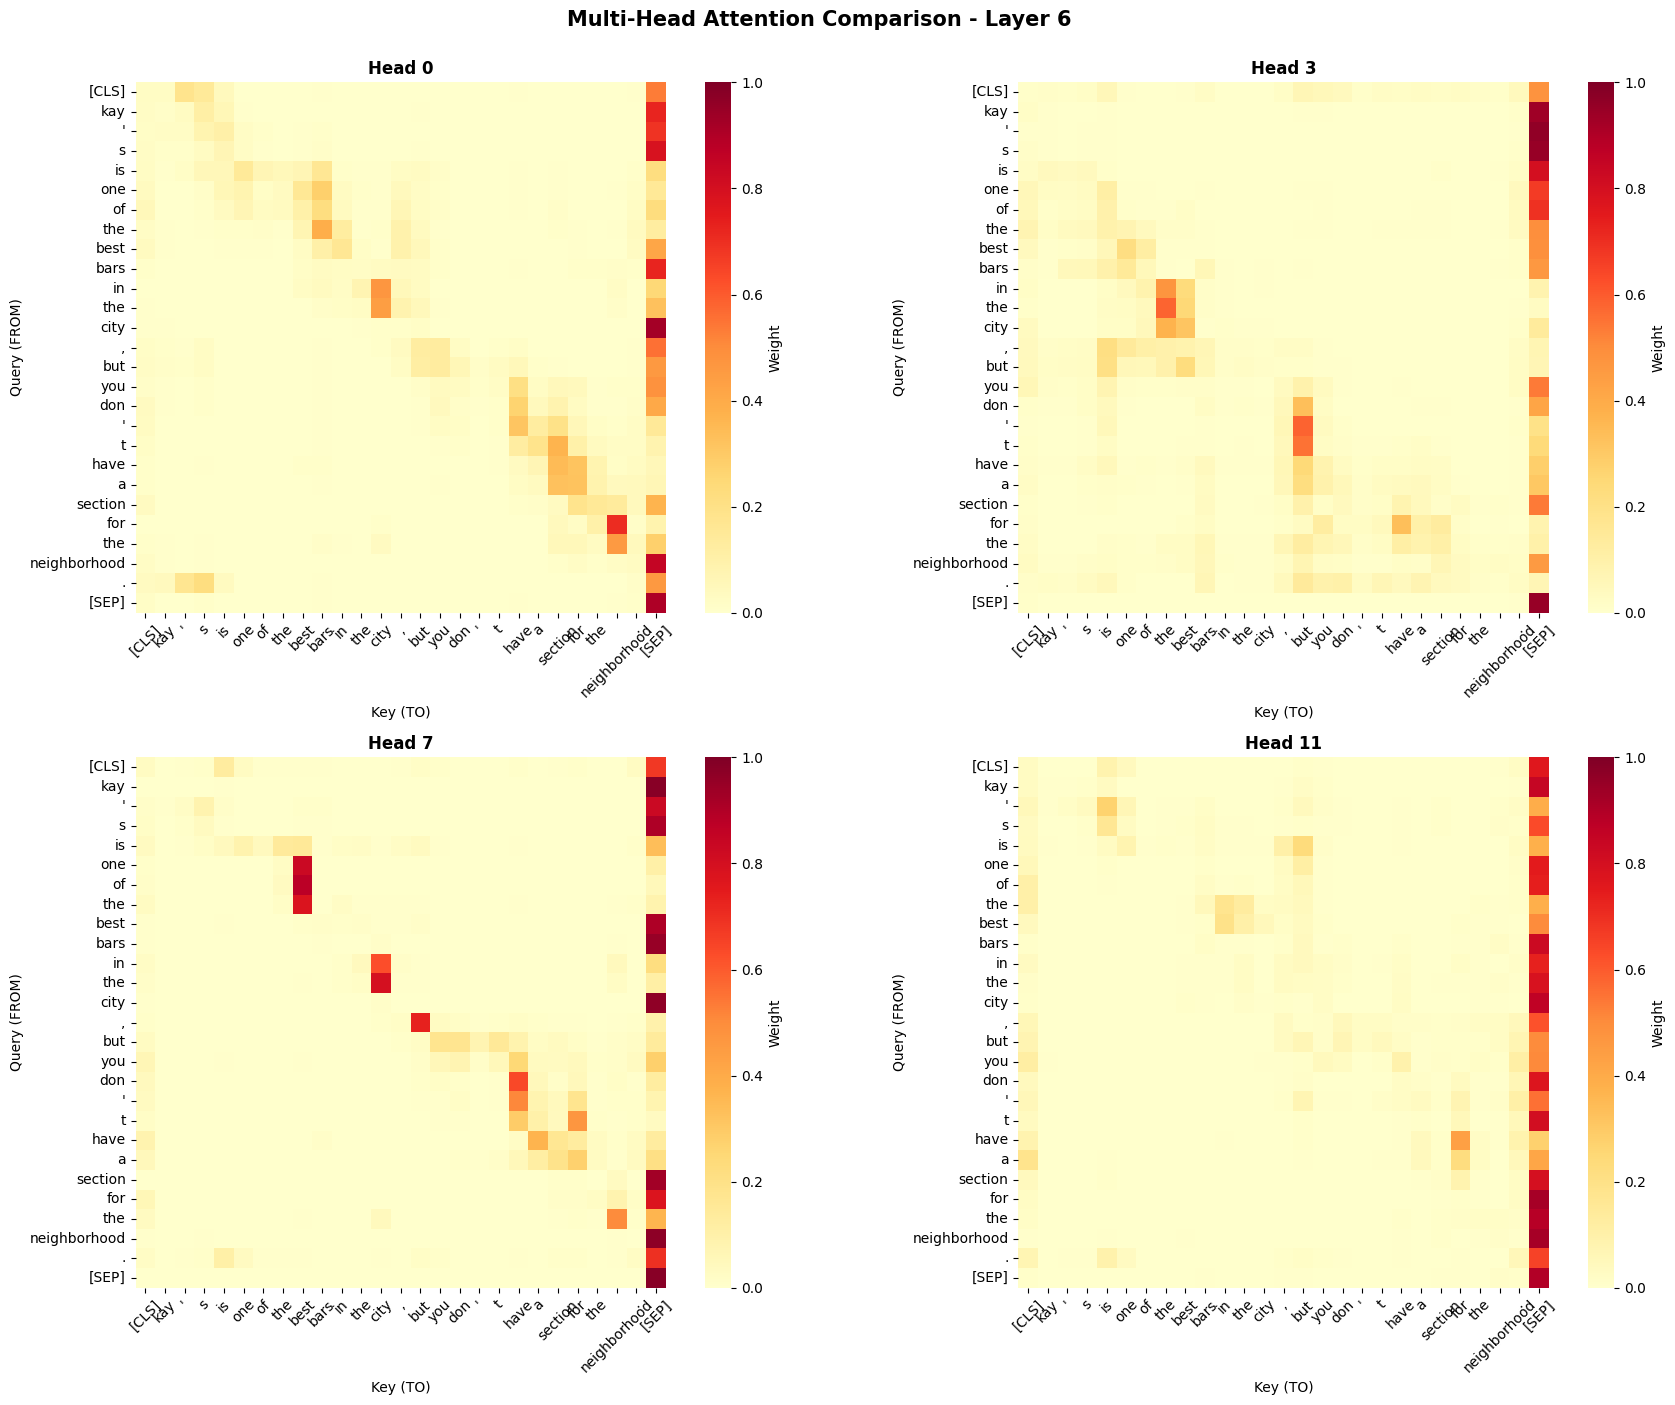

In [7]:
layer_idx = 5  # Layer 6
heads_to_compare = [0, 3, 7, 11]

print(f"Comparing {len(heads_to_compare)} attention heads from Layer {layer_idx+1}...\n")

# Extract attention for all heads in this layer
# attention_weights[layer_idx][0].cpu().numpy() gives (n_heads, seq_len, seq_len)
attn_layer = attention_weights[layer_idx][0].cpu().numpy()

# Plot multi-head comparison
# plot_multihead_attention() from attention_utils
fig = plot_multihead_attention(
    attn_layer,
    tokens,
    layer=layer_idx+1,
    heads=heads_to_compare,
    figsize=(18, 14)
)
plt.show()

### Analysis Questions (Part B)

Compare the 4 attention heads and answer:

1. **Do all heads show the same pattern?**
   - Or do you see diversity?

2. **Can you characterize each head?**
   - Head 0: Local or long-range?
   - Head 3: What relationships does it capture?
   - Head 7: Semantic or syntactic?
   - Head 11: Dense or sparse connections?

3. **Hypothesis:**
   - Do you think different heads specialize in different linguistic phenomena?
   - What evidence supports this?

**TODO:** Write your observations (3-4 sentences):

**YOUR ANALYSIS HERE:**

Comparing the four heads, I notice...




---

# Part C: Analyze Layer-by-Layer Attention (6 minutes)

Do early layers learn different patterns than late layers?

**Hypothesis:** Early layers capture syntax and local patterns, late layers capture semantics and long-range dependencies.

## TODO: Visualize Head 0 Across Multiple Layers

Compare Layers 1, 4, 8, and 12 (all using Head 0).

Comparing Head 0 across multiple layers...



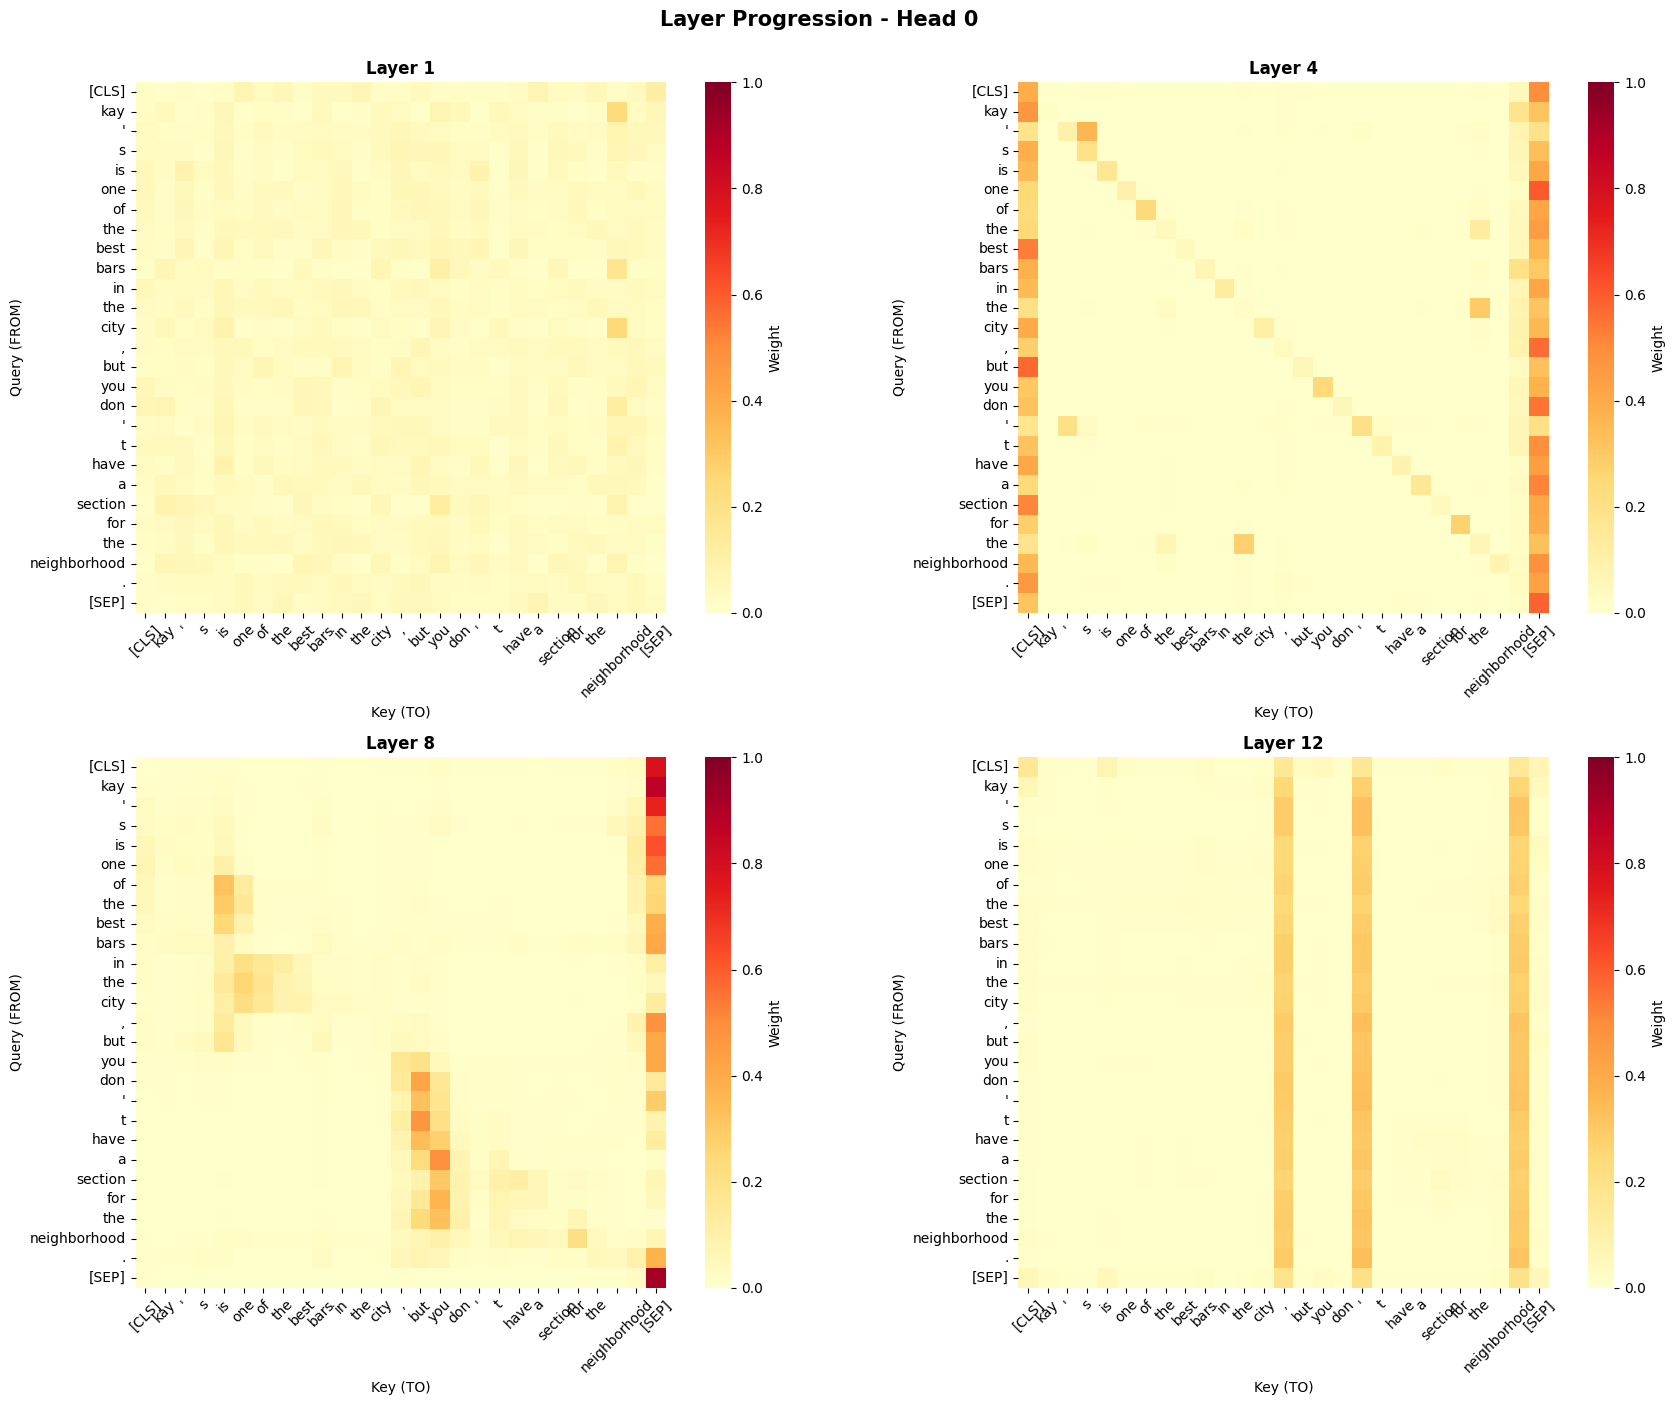

In [8]:
head_idx = 0
layers_to_compare = [0, 3, 7, 11]  # Layers 1, 4, 8, 12 (0-indexed)

print(f"Comparing Head {head_idx} across multiple layers...\n")

# Extract attention weights for each layer (Head 0 only)
# a list of attention matrices, one per layer
attention_by_layer = []
for layer_idx in range(len(attention_weights)):
     attn_layer = attention_weights[layer_idx][0].cpu().numpy()  # (n_heads, seq_len, seq_len)
     attention_by_layer.append(attn_layer)

# Plot layer progression
# plot_layer_progression() from attention_utils
fig = plot_layer_progression(
    attention_by_layer,
    tokens,
    head=head_idx,
    layers=layers_to_compare,
    figsize=(18, 14)
)
plt.show()

### Analysis Questions (Part C)

Compare attention patterns across layers and answer:

1. **Early layers (Layer 1, 4):**
   - Do they focus on nearby tokens (local patterns)?
   - Or long-range connections?
   - What might they be capturing? (syntax? word order?)

2. **Late layers (Layer 8, 12):**
   - Do they show more diffuse attention?
   - Do they connect distant tokens?
   - What might they be capturing? (semantics? meaning?)

3. **Hierarchical learning:**
   - Does your observation support the hypothesis that Transformers learn hierarchically?
   - Early = low-level patterns, Late = high-level meaning?

**TODO:** Write your observations (3-4 sentences):

**YOUR ANALYSIS HERE:**

Looking at the layer progression, I observe...




---

# Summary: What Did You Discover?

## Key Findings

From your visualizations, you should have discovered:

### 1. **Multi-Head Diversity**

### 2. **Hierarchical Learning**

### 3. **Contextualized Understanding**

---

## Why This Matters

**For Content Moderation:**
- You can verify the model focuses on relevant words (not arbitrary patterns)
- Interpretability builds trust in the system
- Can identify and fix problematic attention patterns

**For Deep Learning:**
- Attention visualization reveals what models learn
- Different layers capture different levels of abstraction
- Multi-head attention provides multiple perspectives

**For Modern NLP:**
- This architecture powers GPT, BERT, ChatGPT, Claude
- Understanding attention is key to understanding LLMs
- Interpretability is critical for responsible AI